In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score, KFold, StratifiedKFold
from sklearn.feature_selection import RFECV
import shap
import xgboost as xgb
import optuna
from sklearn import metrics

In [2]:
def gc_stratified_split(df, gc_col, n_bins, random_state, val_size=0.15, test_size=0.15):
    df = df.copy()
    df["_gc_bin"] = pd.qcut(df[gc_col], q=n_bins, labels=False, duplicates="drop")
    train_idx, temp_idx = train_test_split(
        df.index, test_size=val_size + test_size,
        stratify=df["_gc_bin"], random_state=random_state,
    )
    relative_test = test_size / (val_size + test_size)
    val_idx, test_idx = train_test_split(
        temp_idx, test_size=relative_test,
        stratify=df.loc[temp_idx, "_gc_bin"], random_state=random_state,
    )
    return (df.loc[train_idx].drop(columns="_gc_bin"),
            df.loc[val_idx].drop(columns="_gc_bin"),
            df.loc[test_idx].drop(columns="_gc_bin"))

In [3]:
df = pd.read_excel("data_for_classification.xlsx")

In [4]:
FEATURE_COLS = [
    'Length', 'GC-content',
    'Shannon entropy of monomers', 'Shannon entropy of dimers',
    'Mononucleotide repeat fraction', 'Dinucleotide repeat fraction', 
    'Trinucleotide repeat fraction', 'Sum of repeat fractions',
    'Off-target count', 'ΔG of region-target'
]

TARGET_COL = 'Class'
GC_COL = 'GC-content'

In [5]:
n_classes = 3
class_names = {
    0: "Low coverage",
    1: "Moderate coverage",
    2: "High coverage"
}

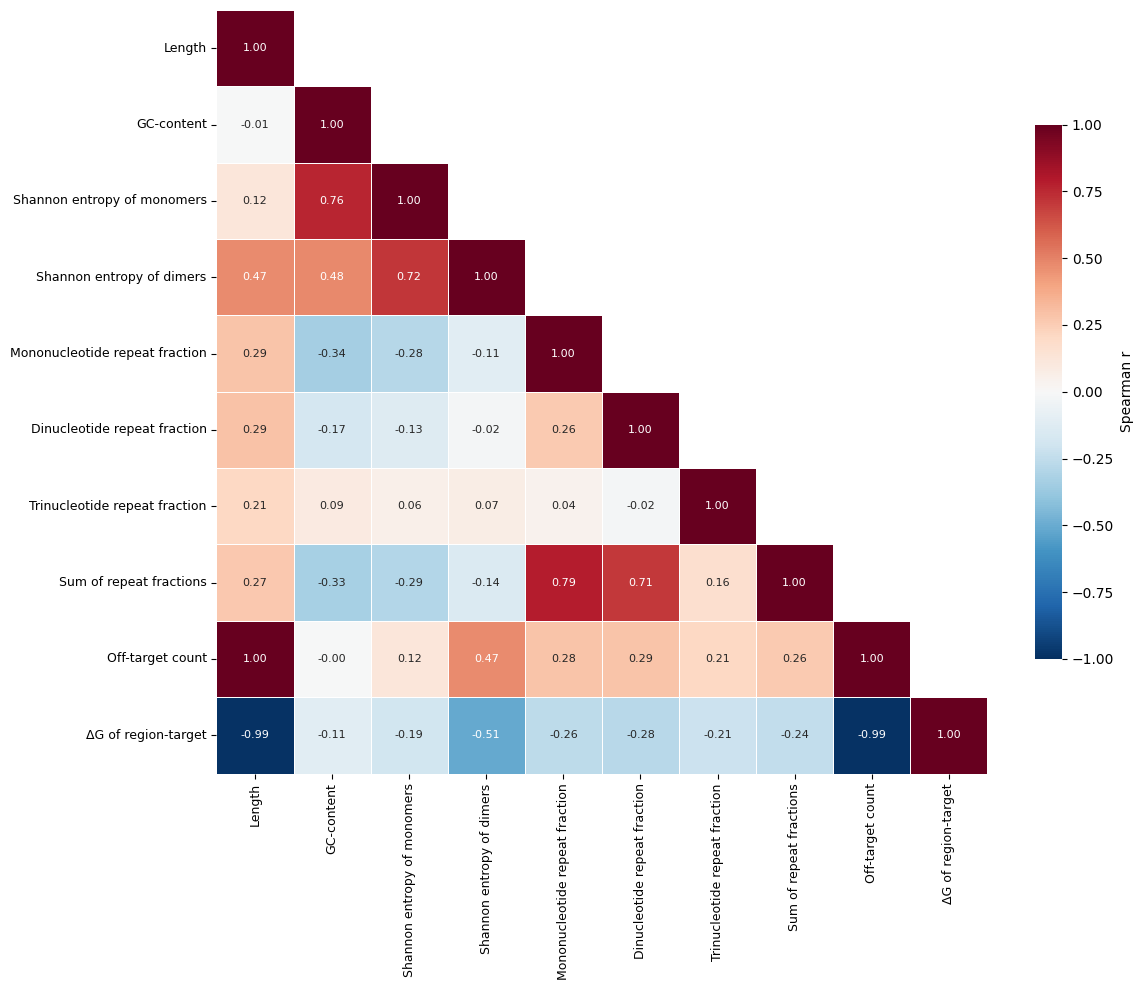

In [6]:
corr_df = df[FEATURE_COLS].corr(method="spearman")

fig, ax = plt.subplots(figsize=(12, 10))
mask = np.zeros_like(corr_df, dtype=bool)
mask[np.triu_indices_from(mask, k=1)] = True

sns.heatmap(
    corr_df,
    mask=mask,
    annot=True, fmt=".2f", annot_kws={"size": 8},
    cmap="RdBu_r", center=0, vmin=-1, vmax=1,
    linewidths=0.4, linecolor="white",
    ax=ax,
    cbar_kws={"shrink": 0.7, "label": "Spearman r"},
)

ax.tick_params(axis="x", rotation=90, labelsize=9)
ax.tick_params(axis="y", rotation=0,  labelsize=9)

plt.tight_layout()
plt.savefig("figs/corr_matrix.png", dpi=300, bbox_inches="tight")
plt.savefig("figs/svg/corr_matrix.svg", bbox_inches="tight")

In [7]:
N_REPEATS = 100

results = []

for seed in range(N_REPEATS):

    train_df, val_df, test_df = gc_stratified_split(
        df,
        GC_COL,
        n_bins=5,
        random_state=seed
    )

    X_train = train_df[FEATURE_COLS].values
    y_train = train_df[TARGET_COL].values

    rfecv = RFECV(
        estimator = xgb.XGBClassifier(
            random_state=42,
            n_jobs=1,
            verbosity=0
        ),
        step=1,
        cv=KFold(
            n_splits=5,
            shuffle=True,
            random_state=seed
        ),
        scoring="f1_macro",
        min_features_to_select=3,
        n_jobs=-1
    )

    rfecv.fit(X_train, y_train)

    for feature, rank, selected in zip(
        FEATURE_COLS,
        rfecv.ranking_,
        rfecv.support_
    ):
        results.append({
            "seed": seed,
            "feature": feature,
            "rank": rank,
            "selected": selected,
            "optimal_n": rfecv.n_features_
        })

results_df = pd.DataFrame(results)

In [8]:
stability_ranking_df = (
    results_df.groupby("feature").agg(
        mean_rank=("rank", "mean"),
        median_rank=("rank", "median"),
        sd_rank=("rank", "std"),

        selection_frequency=("selected", "mean"),
        top5_frequency=(
            "rank",
            lambda x: np.mean(x <= 5)
        )
    ).reset_index()
)

stability_ranking_df = (
    stability_ranking_df.sort_values(
        ["mean_rank", "selection_frequency"],
        ascending=[True, False]
    ).reset_index(drop=True)
)

stability_ranking_df

,feature,mean_rank,median_rank,sd_rank,selection_frequency,top5_frequency
0,GC-content,1.00,1.0,0.000000,1.00,1.00
1,ΔG of region-target,1.18,1.0,0.519907,0.88,1.00
2,Mononucleotide repeat fraction,1.36,1.0,1.059064,0.87,0.98
3,Length,1.37,1.0,1.031376,0.83,0.98
4,Shannon entropy of monomers,1.99,1.0,1.547203,0.58,0.94
5,Sum of repeat fractions,2.14,1.0,1.537544,0.55,0.99
6,Dinucleotide repeat fraction,2.45,2.0,1.838835,0.48,0.90
7,Off-target count,2.71,2.0,2.095184,0.47,0.85
8,Shannon entropy of dimers,3.41,3.0,1.896808,0.26,0.86
9,Trinucleotide repeat fraction,4.07,4.0,2.257446,0.20,0.70


In [9]:
train_df, val_df, test_df = gc_stratified_split(
    df,
    GC_COL,
    n_bins=5,
    random_state=14
)

Baseline model - on features before RFECV

F1-macro score = 0.76
Accuracy score = 0.77
Precision score for test set = 0.75
Recall score for test set = 0.79


Text(95.7222222222222, 0.5, 'True labels\n')

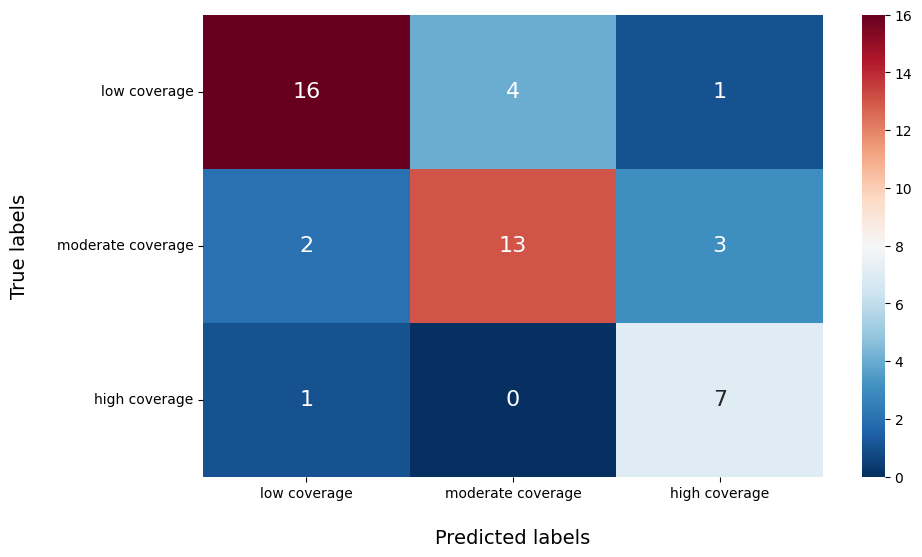

In [ ]:
X_train = train_df[FEATURE_COLS].values
X_val = val_df[FEATURE_COLS].values
X_test = test_df[FEATURE_COLS].values

y_train = train_df[TARGET_COL].values
y_val = val_df[TARGET_COL].values
y_test = test_df[TARGET_COL].values

baseline_model = xgb.XGBClassifier(random_state=42, n_jobs=-1,)
baseline_model.fit(
    X_train, y_train,
    eval_set=[(X_val, y_val)],
    verbose=False)

y_pred = baseline_model.predict(X_test)

f1 = round(metrics.f1_score(y_true = y_test, y_pred = y_pred, average='macro'), 2)
print(f'F1-macro score = {f1}')
acc = round(metrics.accuracy_score(y_true = y_test, y_pred = y_pred), 2)
print(f'Accuracy score = {acc}')
prec = round(metrics.precision_score(y_true = y_test, y_pred = y_pred, average='macro'), 2)
print(f'Precision score for test set = {prec}')
rec = round(metrics.recall_score(y_true = y_test, y_pred = y_pred, average='macro'), 2)
print(f'Recall score for test set = {rec}')
conf_matr = metrics.confusion_matrix(y_true = y_test, y_pred = y_pred)

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(conf_matr, annot = True, cmap = 'RdBu_r', annot_kws = {'size': 16}, fmt=".3g", ax=ax,
            xticklabels=['low coverage', 'moderate coverage', 'high coverage'], yticklabels=['low coverage', 'moderate coverage', 'high coverage'])
plt.yticks(rotation=0)
plt.xlabel(f'\nPredicted labels', fontsize = 14)
plt.ylabel(f'True labels\n', fontsize = 14)

In [11]:
SELECTED_FEATURES = stability_ranking_df[stability_ranking_df["selection_frequency"] > 0.7]["feature"].to_list()

X_train_final = train_df[SELECTED_FEATURES].values
X_val_final = val_df[SELECTED_FEATURES].values
X_test_final = test_df[SELECTED_FEATURES].values

y_train_final = train_df[TARGET_COL].values
y_val_final = val_df[TARGET_COL].values
y_test_final = test_df[TARGET_COL].values

print(f"Subset sizes: train={len(X_train)}, val={len(X_val_final)}, test={len(X_test_final)}")
print(f"mean GC-content: train={train_df[GC_COL].mean():.4f}, "
      f"val={val_df[GC_COL].mean():.4f}, test={test_df[GC_COL].mean():.4f}")

Subset sizes: train=216, val=46, test=47
mean GC-content: train=0.4000, val=0.4018, test=0.3963


Heuristic GC classifier

In [12]:
def GC_classifier(gc: float):
    if gc <= 0.35:
        return 0                    #low_coverage
    elif 0.35 < gc <= 0.43:
        return 1                    #moderate_coverage
    return 2                        #high_coverage

F1-macro score = 0.72
Accuracy score = 0.7
Precision score for test set = 0.77
Recall score for test set = 0.77


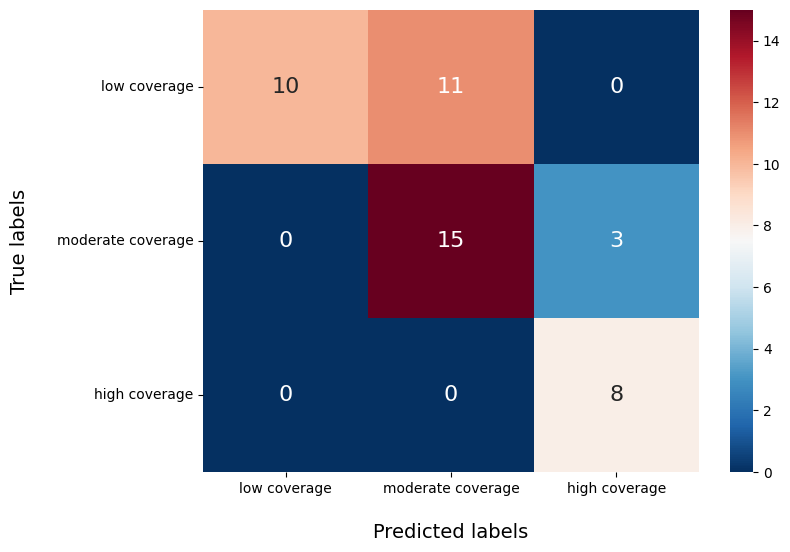

In [22]:
gc_class_pred = {}
y = test_df[TARGET_COL].values

for gc in test_df["GC-content"]:
    pred = GC_classifier(gc)
    gc_class_pred[gc] = pred

temp_df = pd.DataFrame.from_dict(gc_class_pred, orient='index')
temp_df = temp_df.reset_index()
temp_df.columns = ['GC-content', 'GC_Class_pred']
temp_df = test_df.merge(temp_df, on='GC-content')
y_gc_pred = temp_df['GC_Class_pred']

f1 = round(metrics.f1_score(y_true = y, y_pred = y_gc_pred, average='macro'), 2)
print(f'F1-macro score = {f1}')
acc = round(metrics.accuracy_score(y_true = y, y_pred = y_gc_pred), 2)
print(f'Accuracy score = {acc}')
prec = round(metrics.precision_score(y_true = y, y_pred = y_gc_pred, average='macro'), 2)
print(f'Precision score for test set = {prec}')
rec = round(metrics.recall_score(y_true = y, y_pred = y_gc_pred, average='macro'), 2)
print(f'Recall score for test set = {rec}')
conf_matr = metrics.confusion_matrix(y_true = y, y_pred = y_gc_pred)

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(conf_matr, annot = True, cmap = 'RdBu_r', annot_kws = {'size': 16}, fmt=".3g", ax=ax,
            xticklabels=['low coverage', 'moderate coverage', 'high coverage'], yticklabels=['low coverage', 'moderate coverage', 'high coverage'])

plt.xlabel(f'\nPredicted labels', fontsize = 14)
plt.ylabel(f'True labels\n', fontsize = 14)
plt.yticks(rotation=0) 
plt.savefig("figs/test_GC_heuristic_confusion_matrix.png")
plt.savefig("figs/svg/test_GC_heuristic_confusion_matrix.svg")

F1-macro score = 0.62
Accuracy score = 0.61
Precision score for test set = 0.66
Recall score for test set = 0.63


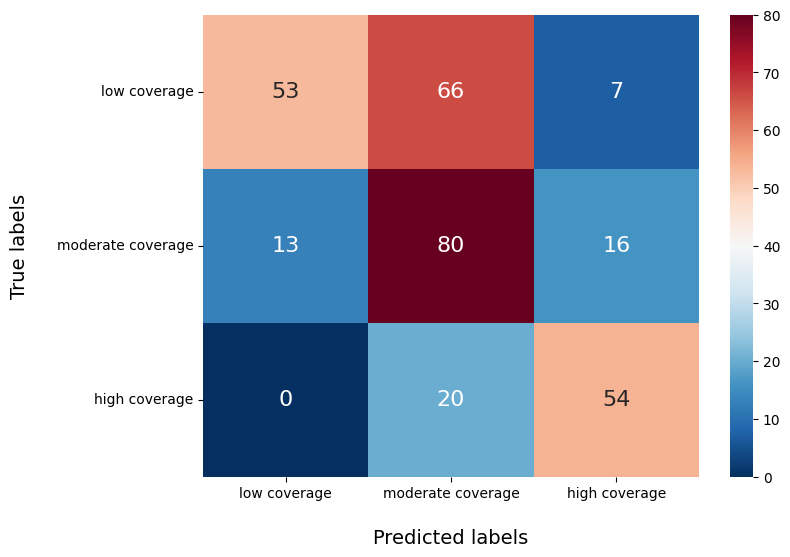

In [23]:
gc_class_pred = {}
y = df[TARGET_COL].values

for gc in df["GC-content"]:
    pred = GC_classifier(gc)
    gc_class_pred[gc] = pred

temp_df = pd.DataFrame.from_dict(gc_class_pred, orient='index')
temp_df = temp_df.reset_index()
temp_df.columns = ['GC-content', 'GC_Class_pred']
temp_df = df.merge(temp_df, on='GC-content')
y_gc_pred = temp_df['GC_Class_pred']

f1 = round(metrics.f1_score(y_true = y, y_pred = y_gc_pred, average='macro'), 2)
print(f'F1-macro score = {f1}')
acc = round(metrics.accuracy_score(y_true = y, y_pred = y_gc_pred), 2)
print(f'Accuracy score = {acc}')
prec = round(metrics.precision_score(y_true = y, y_pred = y_gc_pred, average='macro'), 2)
print(f'Precision score for test set = {prec}')
rec = round(metrics.recall_score(y_true = y, y_pred = y_gc_pred, average='macro'), 2)
print(f'Recall score for test set = {rec}')
conf_matr = metrics.confusion_matrix(y_true = y, y_pred = y_gc_pred)

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(conf_matr, annot = True, cmap = 'RdBu_r', annot_kws = {'size': 16}, fmt=".3g", ax=ax,
            xticklabels=['low coverage', 'moderate coverage', 'high coverage'], yticklabels=['low coverage', 'moderate coverage', 'high coverage'])

plt.xlabel(f'\nPredicted labels', fontsize = 14)
plt.ylabel(f'True labels\n', fontsize = 14)
plt.yticks(rotation=0) 
plt.savefig("figs/whole_dataset_GC_heuristic_confusion_matrix.png", dpi=300)
plt.savefig("figs/svg/whole_dataset_GC_heuristic_confusion_matrix.svg")

Final model - based on selected by RFECV features

In [15]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

def objective(trial):
    params = {'n_estimators': trial.suggest_int('n_estimators', 300, 600),
              'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.1),
              'min_child_weight': trial.suggest_int('min_child_weight', 2, 10),
              'gamma': trial.suggest_float('gamma', 0.01, 0.1),
              'reg_alpha': trial.suggest_float('reg_alpha', 1e-4, 1e-2, log=True),
              'reg_lambda': trial.suggest_float('reg_lambda', 1e-4, 1e-2, log=True)}

    xgbopt = xgb.XGBClassifier(objective="multi:softmax", random_state=42, **params)

    scores = cross_val_score(
        xgbopt,
        X_train_final,
        y_train_final,
        cv=cv,
        scoring="f1_macro",
        n_jobs=-1
    )

    return scores.mean()

study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=0))
study.optimize(objective, n_trials=100)

print("Best parameters:", study.best_params)
print("Best F1-macro score:", study.best_value)

[I 2026-11-17 17:39:53,419] A new study created in memory with name: no-name-b8636f33-5d87-477d-98c2-16ee151514ea
[I 2026-11-17 17:39:53,918] Trial 0 finished with value: 0.6404583402133313 and parameters: {'n_estimators': 465, 'learning_rate': 0.07436704297351776, 'min_child_weight': 7, 'gamma': 0.05903948646972072, 'reg_alpha': 0.0007035737028722148, 'reg_lambda': 0.0019578897201213002}. Best is trial 0 with value: 0.6404583402133313.
[I 2026-11-17 17:39:54,319] Trial 1 finished with value: 0.6419173735895851 and parameters: {'n_estimators': 431, 'learning_rate': 0.09025957007038718, 'min_child_weight': 10, 'gamma': 0.04450973669432, 'reg_alpha': 0.0038322168504927897, 'reg_lambda': 0.0011423254155608373}. Best is trial 1 with value: 0.6419173735895851.
[I 2026-11-17 17:39:54,804] Trial 2 finished with value: 0.6316133992396264 and parameters: {'n_estimators': 470, 'learning_rate': 0.0933036974463395, 'min_child_weight': 2, 'gamma': 0.017841636973138664, 'reg_alpha': 0.00010975815419

Best parameters: {'n_estimators': 422, 'learning_rate': 0.025885105295760533, 'min_child_weight': 3, 'gamma': 0.01559862102254301, 'reg_alpha': 0.0012212024685187516, 'reg_lambda': 0.0065786037983051856}
Best F1-macro score: 0.6649228635603849


In [16]:
final_model = xgb.XGBClassifier(objective="multi:softmax", random_state=42, **study.best_params)
final_model.fit(
    X_train_final, y_train_final,
    eval_set=[(X_val_final, y_val_final)],
    verbose=False
)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=0.01559862102254301, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.025885105295760533, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=None, max_leaves=None,
              min_child_weight=3, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=422, n_jobs=None,
              num_parallel_tree=None, ...)

F1-macro score = 0.81
Accuracy score = 0.83
Precision score for test set = 0.8
Recall score for test set = 0.84


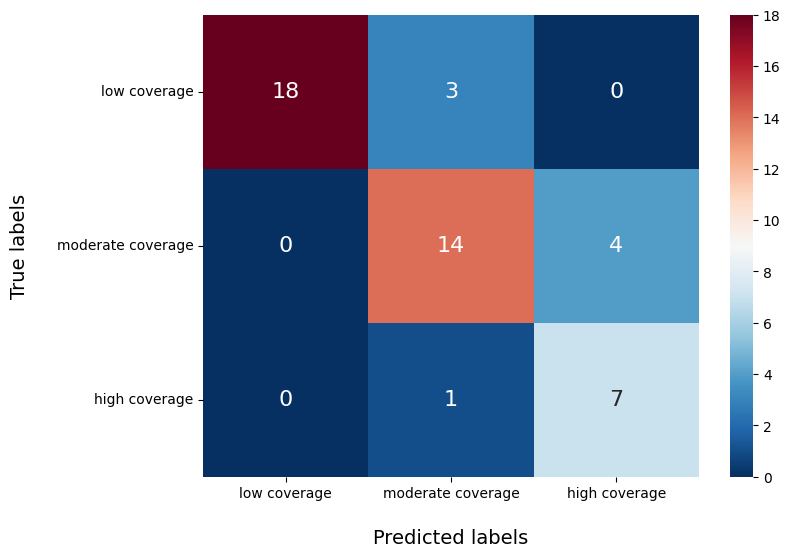

In [24]:
y_test_pred = final_model.predict(X_test_final)

f1 = round(metrics.f1_score(y_true = y_test_final, y_pred = y_test_pred, average='macro'), 2)
print(f'F1-macro score = {f1}')
acc = round(metrics.accuracy_score(y_true = y_test_final, y_pred = y_test_pred), 2)
print(f'Accuracy score = {acc}')
prec = round(metrics.precision_score(y_true = y_test_final, y_pred = y_test_pred, average='macro'), 2)
print(f'Precision score for test set = {prec}')
rec = round(metrics.recall_score(y_true = y_test_final, y_pred = y_test_pred, average='macro'), 2)
print(f'Recall score for test set = {rec}')

conf_matr = metrics.confusion_matrix(y_true = y_test_final, y_pred = y_test_pred)
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(conf_matr, annot = True, cmap = 'RdBu_r', annot_kws = {'size': 16}, fmt=".3g", ax=ax,
            xticklabels=['low coverage', 'moderate coverage', 'high coverage'], yticklabels=['low coverage', 'moderate coverage', 'high coverage'])
plt.yticks(rotation=0)
plt.xlabel(f'\nPredicted labels', fontsize = 14)
plt.ylabel(f'True labels\n', fontsize = 14)
plt.savefig("figs/test_confusion_matrix.png", dpi=300)
plt.savefig("figs/svg/test_confusion_matrix.svg")

In [ ]:
explainer = shap.TreeExplainer(final_model)
shap_values = explainer.shap_values(X_test_final)
shap_values = [shap_values[:, :, k] for k in range(n_classes)]

In [19]:
global_importance = {}

for k in range(n_classes):
    mean_abs_shap = np.abs(shap_values[k]).mean(axis=0)

    global_importance[class_names[k]] = (
        pd.Series(
            mean_abs_shap,
            index=SELECTED_FEATURES
        )
        .sort_values(ascending=False)
    )